In [1]:
import scanpy as sc
import os
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import random
import pandas as pd

SEED = 0
np.random.seed(SEED)
random.seed(SEED)


my_cmap = LinearSegmentedColormap.from_list(
    "soft_rdbl", ["#53b1dc", "#FFFFFF", "#EE6677"], N=256
)





figure_save_path = "../results/Supplementary_Fig_4_figures"
os.makedirs(figure_save_path, exist_ok=True)




## Supplementary Fig. 4c

In [2]:
adata = sc.read("../data/Cultured_fibroblasts_min.h5ad")


## Fig. 6d

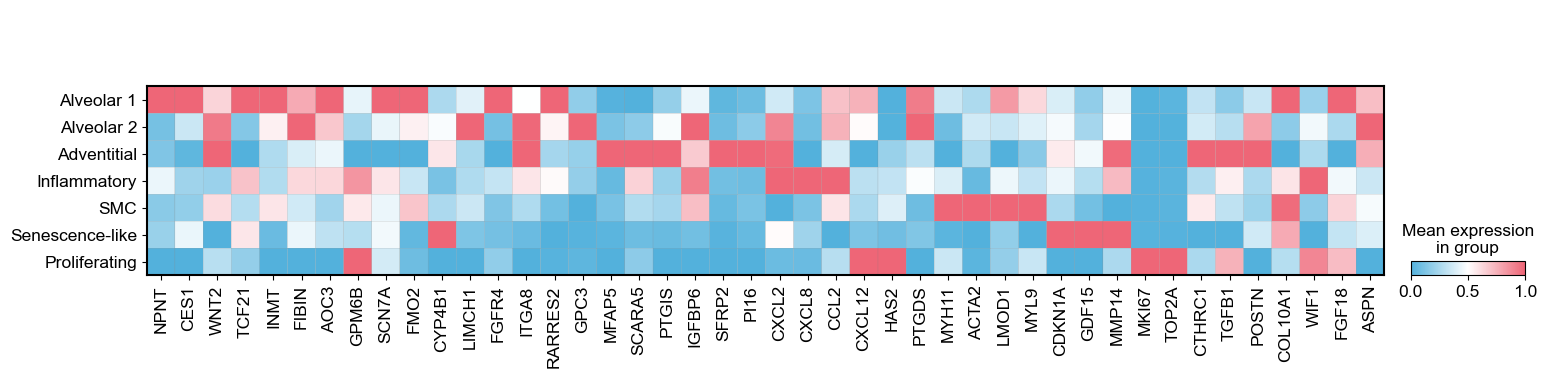

In [3]:
fibroblast_markers = {
    "Alveolar": ["NPNT", "CES1", "WNT2", "TCF21", "INMT", "FIBIN",
                 "AOC3", "GPM6B", "SCN7A", "FMO2", "CYP4B1", "LIMCH1",
                 "FGFR4", "ITGA8", "RARRES2", "GPC3"],
    "Adventitial": ["MFAP5", "SCARA5", "PTGIS", "IGFBP6", "SFRP2", "PI16"],
    "Inflammatory": ["CXCL2", "CXCL8", "CCL2", "CXCL12", "HAS2", "PTGDS"],
    "SMC": ["MYH11", "ACTA2", "LMOD1", "MYL9"],
    "Senescence-like": ["CDKN1A", "GDF15", "MMP14"],
    "Proliferating": ["MKI67", "TOP2A"],
    "CTHRC1+": ["CTHRC1", "TGFB1", "POSTN", "COL10A1"],
    "Peribronchial": ["WIF1", "FGF18", "ASPN"]
}

fibroblast_markers_list = []
for category in fibroblast_markers.values():
    fibroblast_markers_list.extend(category)


with plt.rc_context({'font.size': 15, 'figure.figsize': (4, 3)}):
    fig = sc.pl.matrixplot(
        adata,
        var_names=fibroblast_markers_list,
        groupby='annotation',
        standard_scale='var',
        cmap=my_cmap,
        return_fig=True,
        linewidths=3
    )


    fig.savefig(f'{figure_save_path}/Cultured_fibroblasts_heatmap_all_WL_markers.pdf', bbox_inches='tight')
    plt.show()